<center><p float="center">
  <img src="https://upload.wikimedia.org/wikipedia/commons/e/e9/4_RGB_McCombs_School_Brand_Branded.png" width="300" height="100"/>
  <img src="https://mma.prnewswire.com/media/1458111/Great_Learning_Logo.jpg?p=facebook" width="200" height="100"/>
</p></center>

<h1><center><font size=10>Artificial Intelligence and Machine Learning</center></font></h1>



<center> <font size=6> Project Python Foundations: FoodHub Data Analysis

<center><img src="https://www.netsolutions.com/wp-content/uploads/2022/10/essential-features-of-building-an-on-demand-food-ordering-app.jpg" width="720"></center>


### Context

The number of restaurants in New York is increasing day by day. Lots of students and busy professionals rely on those restaurants due to their hectic lifestyles. Online food delivery service is a great option for them. It provides them with good food from their favorite restaurants. A food aggregator company FoodHub offers access to multiple restaurants through a single smartphone app.

The app allows the restaurants to receive a direct online order from a customer. The app assigns a delivery person from the company to pick up the order after it is confirmed by the restaurant. The delivery person then uses the map to reach the restaurant and waits for the food package. Once the food package is handed over to the delivery person, he/she confirms the pick-up in the app and travels to the customer's location to deliver the food. The delivery person confirms the drop-off in the app after delivering the food package to the customer. The customer can rate the order in the app. The food aggregator earns money by collecting a fixed margin of the delivery order from the restaurants.

### Objective

The food aggregator company has stored the data of the different orders made by the registered customers in their online portal. They want to analyze the data to get a fair idea about the demand of different restaurants which will help them in enhancing their customer experience. Suppose you are hired as a Data Scientist in this company and the Data Science team has shared some of the key questions that need to be answered. Perform the data analysis to find answers to these questions that will help the company to improve the business.

### Data Description

The data contains the different data related to a food order. The detailed data dictionary is given below.

### Data Dictionary

* order_id: Unique ID of the order
* customer_id: ID of the customer who ordered the food
* restaurant_name: Name of the restaurant
* cuisine_type: Cuisine ordered by the customer
* cost_of_the_order: Cost of the order
* day_of_the_week: Indicates whether the order is placed on a weekday or weekend (The weekday is from Monday to Friday and the weekend is Saturday and Sunday)
* rating: Rating given by the customer out of 5
* food_preparation_time: Time (in minutes) taken by the restaurant to prepare the food. This is calculated by taking the difference between the timestamps of the restaurant's order confirmation and the delivery person's pick-up confirmation.
* delivery_time: Time (in minutes) taken by the delivery person to deliver the food package. This is calculated by taking the difference between the timestamps of the delivery person's pick-up confirmation and drop-off information

### Let us start by importing the required libraries

In [ ]:
# Installing the libraries with the specified version.
!pip install numpy==2.0.2 pandas==2.2.2 matplotlib==3.10.0 seaborn==0.13.2 -q --user

**Note**:
- After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for Jupyter Notebook), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.

In [2]:
# import libraries for data manipulation
import numpy as np
import pandas as pd

# import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

### Understanding the structure of the data

In [3]:
#Load this first to get the google drive mounted (needs permissions - grant ok and hit continue)
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
#data csv is loaded on my google drive, called foodhub_order.csv so from google.colab mount drive and import path
#this is my personal data path drive - so the one for the grader of this project will be different
path = '/content/drive/MyDrive/ColabNotebooks/foodhub_order.csv'

In [6]:
#import the csv from my google drive above
df = pd.read_csv(path)

In [7]:
#use df.head() to read in the first five rows of the data
df.head()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24


### **Question 1:** How many rows and columns are present in the data? [0.5 mark]

In [8]:
#use df.shape to get the rows and columns
print("Number of rows:", df.shape[0], "and Number of Columns:", df.shape[1])

Number of rows: 1898 and Number of Columns: 9


#### Observations:
We see that there are 1898 unique rows of data with 9 columns with descriptive names.

### **Question 2:** What are the datatypes of the different columns in the dataset? (The info() function can be used) [0.5 mark]

In [9]:
#we have two options here, df.info() is more comprehensive and will use this, df.datatypes gives us the datatypes of each column, and will not use on this question
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1898 entries, 0 to 1897
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               1898 non-null   int64  
 1   customer_id            1898 non-null   int64  
 2   restaurant_name        1898 non-null   object 
 3   cuisine_type           1898 non-null   object 
 4   cost_of_the_order      1898 non-null   float64
 5   day_of_the_week        1898 non-null   object 
 6   rating                 1898 non-null   object 
 7   food_preparation_time  1898 non-null   int64  
 8   delivery_time          1898 non-null   int64  
dtypes: float64(1), int64(4), object(4)
memory usage: 133.6+ KB


#### Observations:
We are given the column names here, of which there are 9 with descriptive names to them, as well as the count of data. All columns have 1898 rows of data. There is a mixture of Float, Interger and Object data types.


### **Question 3:** Are there any missing values in the data? If yes, treat them using an appropriate method. [1 mark]

In [10]:
#first, are there any missing values? quick and easy use df.isnull() and put into variable
are_there_any_nulls = df.isnull().values.any()
print(are_there_any_nulls)

#check if 'are_there_any_nulls' is True or False. If false, don't need to do anything. If true, then we will drop the row(s).

if are_there_any_nulls == True:
  df_cleaned = df.dropna()
  print('The null values have been removed')
else:
  print('There were no null values that were found in the data.\nIt is okay to proceed')

False
There were no null values that were found in the data.
It is okay to proceed


#### Observations:
The answer came back "NO", so there is no need to treat them. However, for this project, any row with null data may skew the results, so best to remove these if found - however, there were no NULLs.
The Column for RATING has "not Given" - this is not a Null value, however, if we need to work with this, then we need to set it to a numeric value, the entire column, which we will do in question 13.


### **Question 4:** Check the statistical summary of the data. What is the minimum, average, and maximum time it takes for food to be prepared once an order is placed? [2 marks]

In [11]:
#Store the Minimum, Average and Maximum times into variables and then print them out
minfpt = np.min(df.food_preparation_time)
maxfpt = np.max(df.food_preparation_time)
avgfpt = np.mean(df.food_preparation_time)
print ('The minimum time it takes for food to be prepared is:', minfpt, 'minutes.')
print ('The maximum time it takes for food to be prepared is:', maxfpt, 'minutes.')
print ('The average/mean time it takes for food to be prepared is:', round(avgfpt), 'minutes.')


The minimum time it takes for food to be prepared is: 20 minutes.
The maximum time it takes for food to be prepared is: 35 minutes.
The average/mean time it takes for food to be prepared is: 27 minutes.


#### Observations:
The data is pretty normalized with the bell shaped structure.
The minimum time it takes to prepare food is 20 minutes, the maximum is 35 minutes, which gives a mean time of 27 minutes, overall.

### **Question 5:** How many orders are not rated? [1 mark]

In [12]:
# get the count of Not Given and then divide by the totals which is shape(0)
Orders_not_rated = df['rating'].value_counts()['Not given']
Orders_NR_Mean = (Orders_not_rated/df.shape[0])

print('There are', Orders_not_rated, 'orders that were not given a rating, which is', round(Orders_NR_Mean,2),'% of the total.')

There are 736 orders that were not given a rating, which is 0.39 % of the total.


#### Observations:
736 orders are not rated, which is 38.78% of the data, rounded to 39%. We would need to work with the ones (data "not rated") not given a rating if we were to focus on that column.

### Exploratory Data Analysis (EDA)

### Univariate Analysis

### **Question 6:** Explore all the variables and provide observations on their distributions. (Generally, histograms, boxplots, countplots, etc. are used for univariate exploration.) [9 marks]

In [13]:
#GENERAL 1. Get total orders and then min, then get total orders then Average Orders
#Then review Order Cost, Food Prep Time, Delivery Times, Cuisine Type, Restaurant Ratings and Top Restaurant
order_counts = df['customer_id'].value_counts()
min_orders = order_counts.min()
total_customers_with_min_orders = (order_counts == min_orders).sum()
total_orders = df['order_id'].count()
orders_res = df['restaurant_name'].value_counts()
avg_orders = orders_res.mean()

print('Number of customers who placed minimum', min_orders, 'orders is total', total_customers_with_min_orders, 'out of', total_orders, 'total orders')
print('\n')
print('Average number of orders per restaurant:', round(avg_orders,2))
print('\n')
print('Review Order Costs, Preparation Time and Delivery Times in Graphs below')
print('\n')




Number of customers who placed minimum 1 orders is total 784 out of 1898 total orders


Average number of orders per restaurant: 10.66


Review Order Costs, Preparation Time and Delivery Times in Graphs below




Cost of Order by cuisine type in a Histogram graph

Axes(0.125,0.11;0.775x0.77)




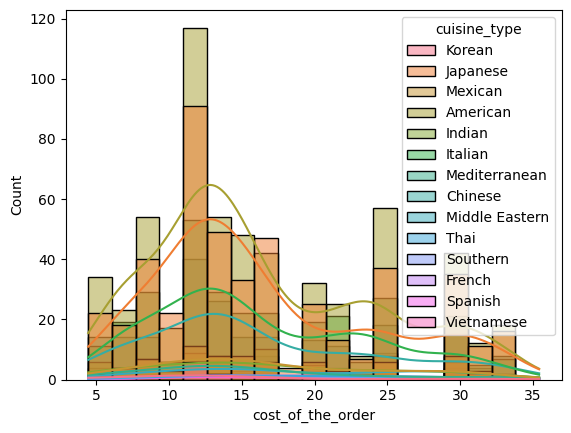

In [14]:
#Order Cost HISTOGRAM
print('Cost of Order by cuisine type in a Histogram graph\n')
ploth = sns.histplot(data=df, x='cost_of_the_order', hue='cuisine_type', kde=True)
print(ploth)
print('\n')



Cost of Order in a Box Plot graph

Axes(0.125,0.11;0.775x0.77)




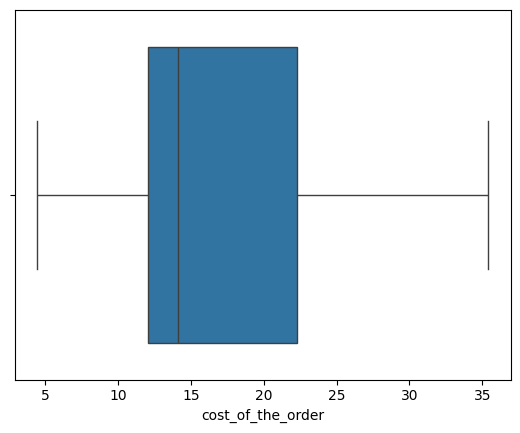

In [15]:
#Order Cost BOXPLOT
print('Cost of Order in a Box Plot graph\n')
plotb = sns.boxplot(data=df, x='cost_of_the_order')
print(plotb)
print('\n')



Food Preparation Times in a Histogram graph
Axes(0.125,0.11;0.775x0.77)




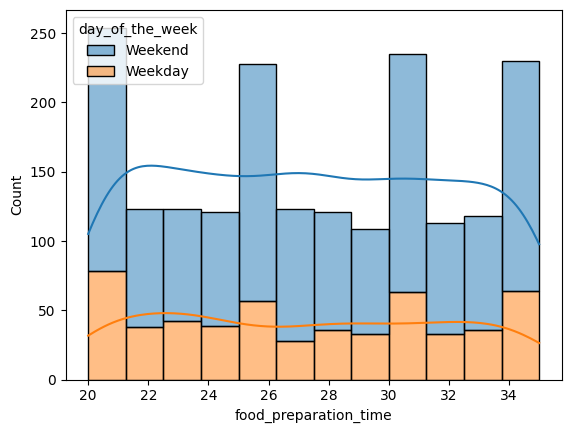

In [16]:
#Food Prep HISTOGRAM
print('Food Preparation Times in a Histogram graph')
plotfp = sns.histplot(data=df, x='food_preparation_time', hue='day_of_the_week', kde=True, multiple='stack')
print(plotfp)
print('\n')



Delivery Times in a Boxplot graph
Axes(0.125,0.11;0.775x0.77)




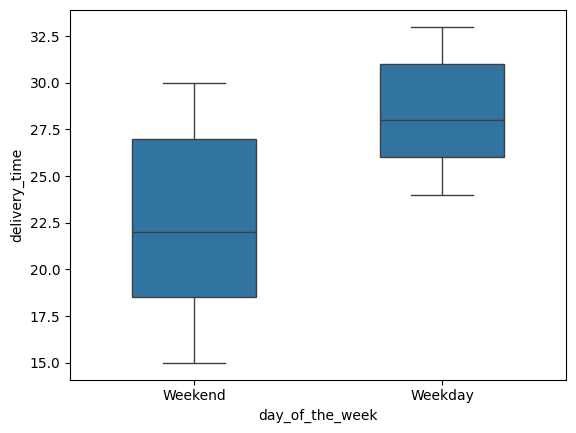

In [17]:
#Delivery time - BoxPlot
print('Delivery Times in a Boxplot graph')
plot_deltime = sns.boxplot(data=df, x='day_of_the_week', y='delivery_time', width=0.5)
print(plot_deltime)
print('\n')

Cuisine Type in a countplot graph
Axes(0.125,0.11;0.775x0.77)


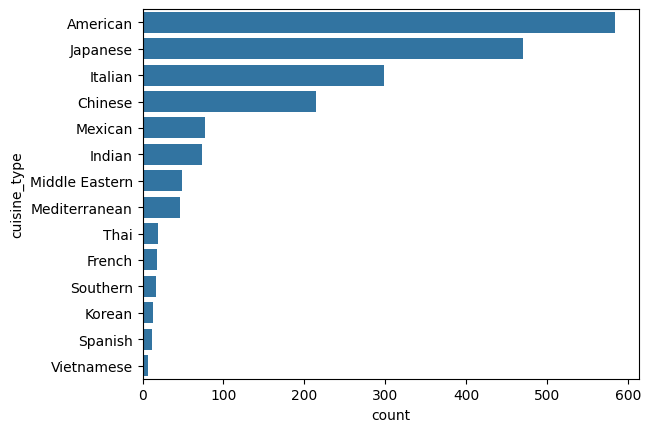

In [18]:
#Cuisine Type
print('Cuisine Type in a countplot graph')
plotct = sns.countplot(data=df, y='cuisine_type', order=df['cuisine_type'].value_counts().index)
print(plotct)

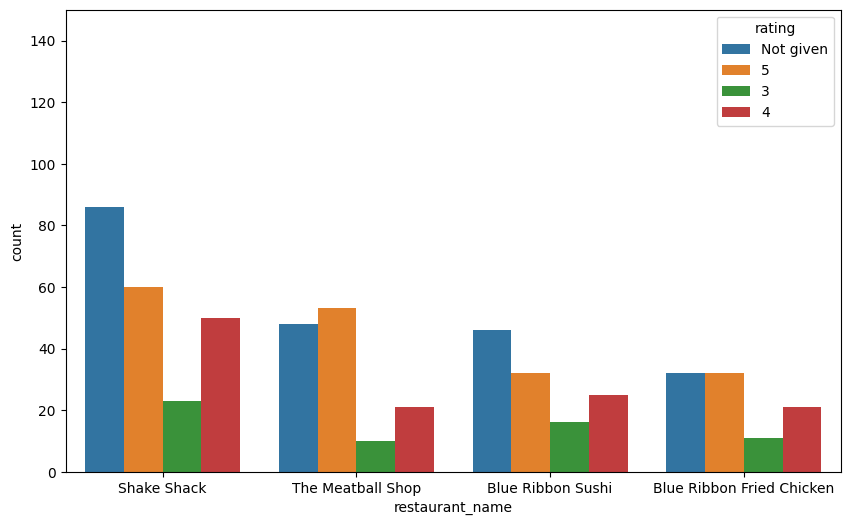

In [19]:
#Restaurant Ratings just top 4
get_rated_orders = df[df['rating'] != 'Not given']
plt.figure(figsize=(10, 6))
plotrr=sns.countplot(data=df, x='restaurant_name', hue='rating', order=get_rated_orders['restaurant_name'].value_counts().index[:4])
plt.ylim(0, 150)
plt.show()


#### Observations:
Indian and Japanese are the most costly cuisines, whereas Spanish and Vietnamese are the least expensive. It appears that the cost of the orders are slightly right skewed which may be due to people not buying as much of the expensive cuisines and sticking more with the normal.

Food preparation is fairly consistent, with flucations between weekday and weekend preparation, which may be the result of more orders on the weekends creating longer preparation times.

Delivery took certainly longer over the weekdays, which again may be because of traffic issues depending on the locations.

American, Japanese, Italian and Chinese cuisines are by far the most ordered

And the rating leaders are The Shake Shack, The Meatball Shop and Blue Ribbon Sushi.

### **Question 7**: Which are the top 5 restaurants in terms of the number of orders received? [1 mark]

In [20]:
# The top5 restaurants are
top5_rest = df['restaurant_name'].value_counts().nlargest(5).to_string()
print('The Top 5 Restaurants are:\n', top5_rest)

The Top 5 Restaurants are:
 restaurant_name
Shake Shack                  219
The Meatball Shop            132
Blue Ribbon Sushi            119
Blue Ribbon Fried Chicken     96
Parm                          68


#### Observations:
Shake Shack has the largest amounts of orders received and is far in front of the second place restarant

### **Question 8**: Which is the most popular cuisine on weekends? [1 mark]

In [21]:
#here we need to get the weekend values first, and then we can see the value counts for it
weekend = df[df['day_of_the_week'] == 'Weekend']
best_cuisine = weekend['cuisine_type'].value_counts().nlargest(1).to_string()
print('The most populare cuisine on weekends is:\n', best_cuisine)

The most populare cuisine on weekends is:
 cuisine_type
American    415


#### Observations:
American is the most popular cusine on the weekends

### **Question 9**: What percentage of the orders cost more than 20 dollars? [2 marks]

In [22]:
#First we need to get the total orders > 20, then we can get the percentage of it from the total
orders_morethan20 = len(df[df["cost_of_the_order"]>20])
total_orders = len(df.index)
perc_orders_morethan20 = (orders_morethan20 / total_orders)
print('The percentage of orders over $20 is:', round(perc_orders_morethan20,2),'%')

The percentage of orders over $20 is: 0.29 %


#### Observations:
555 orders, or roughly over a quarter of the orders are over $20, meaning a majority of purchases are below this, suggesting more casual pick up of meals instead of expensive dining.

### **Question 10**: What is the mean order delivery time? [1 mark]

In [23]:
# Write the code here
mean_del_time = df['delivery_time'].mean()
print('The mean order delivery time is:', round(mean_del_time,2), 'minutes')

The mean order delivery time is: 24.16 minutes


#### Observations:
The mean of the delivery time is 24.16 minutes, or just under 1/2 hour.

### **Question 11:** The company has decided to give 20% discount vouchers to the top 3 most frequent customers. Find the IDs of these customers and the number of orders they placed. [1 mark]

In [24]:
# obtain the top three customers and then the total of the orders they placed
top_three_customers = df['customer_id'].value_counts().head(3)
print("Top 3 Most Frequent Customers:", top_three_customers)


Top 3 Most Frequent Customers: customer_id
52832    13
47440    10
83287     9
Name: count, dtype: int64


#### Observations:
The top three customers are listed, with just their IDs. There are no names given. We would need to find the names/emails in order to give the discount voucher.

### Multivariate Analysis

### **Question 12**: Perform a multivariate analysis to explore relationships between the important variables in the dataset. (It is a good idea to explore relations between numerical variables as well as relations between numerical and categorical variables) [10 marks]


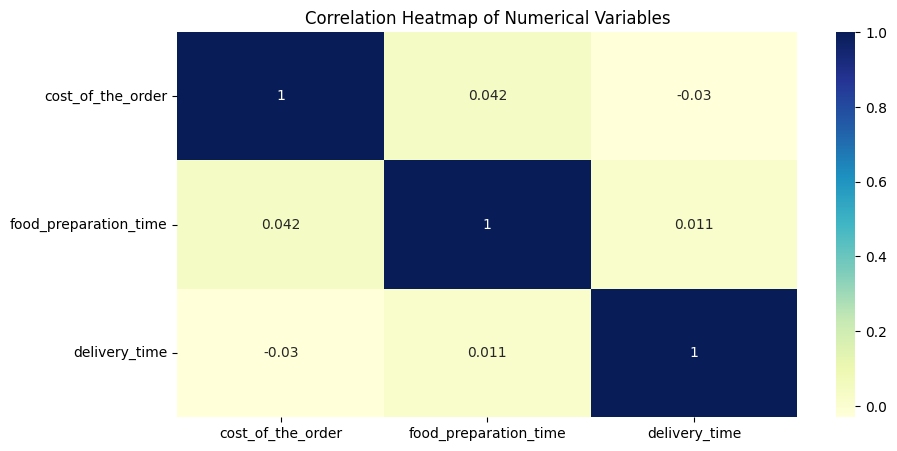

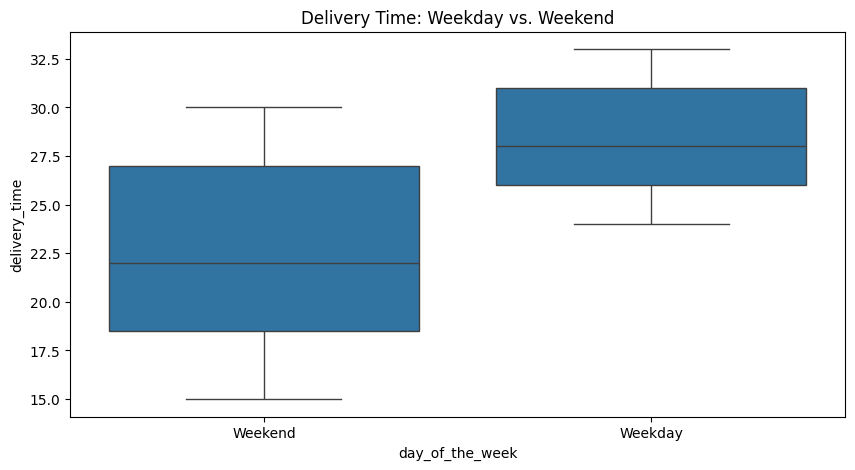

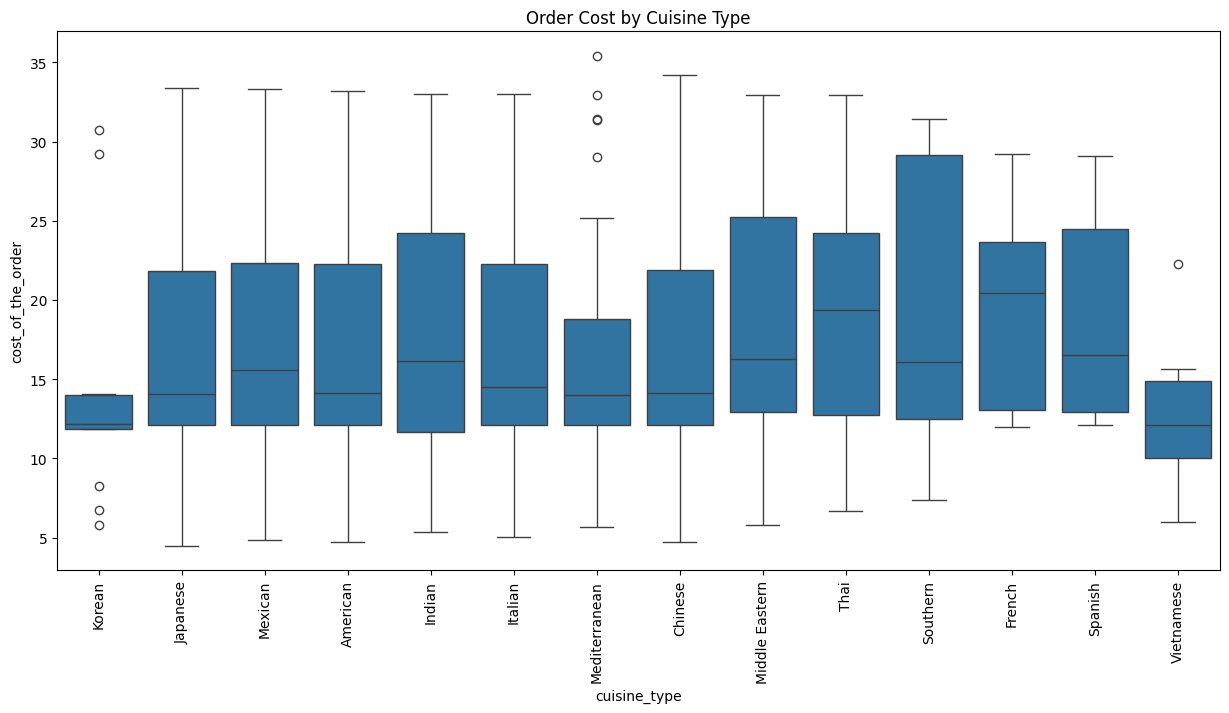

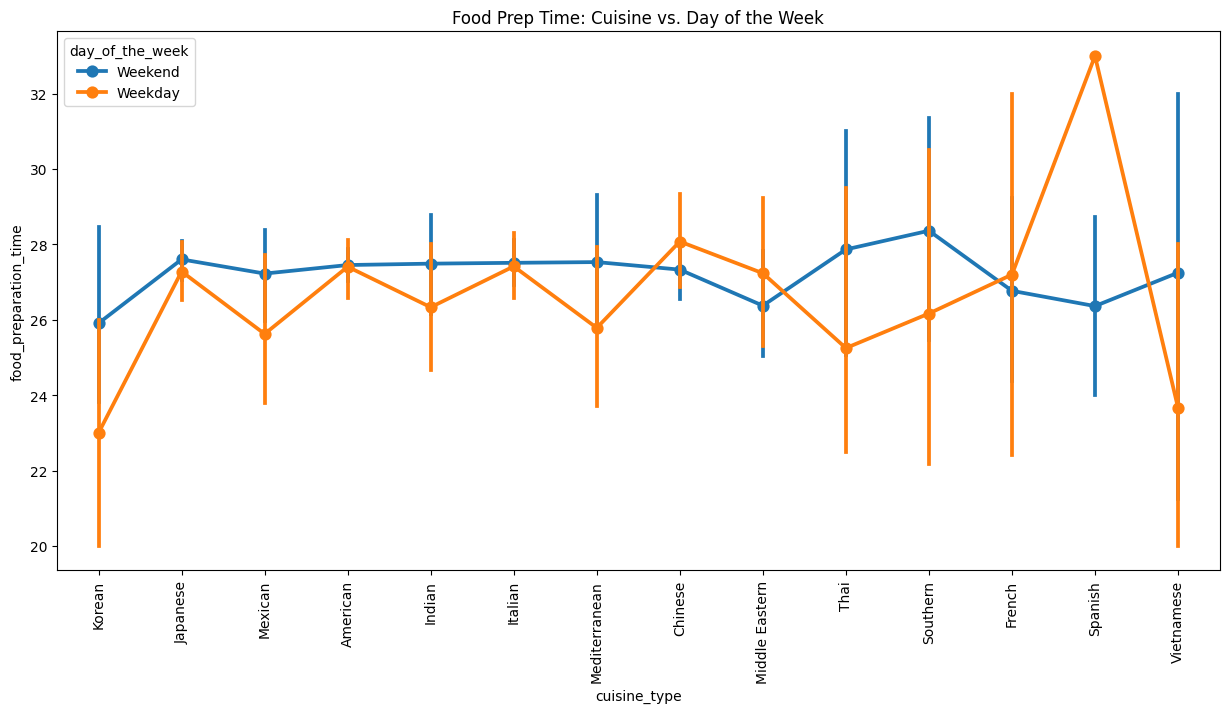

In [25]:
#Numerical-Numerical Analysis of three - Cost, Preparation and Delivery Time
plt.figure(figsize=(10, 5))
sns.heatmap(df[['cost_of_the_order', 'food_preparation_time', 'delivery_time']].corr(), annot=True, cmap='YlGnBu')
plt.title('Correlation Heatmap of Numerical Variables')
plt.show()

#Date-Categorial Analysis of Week Day and Delivery Time
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='day_of_the_week', y='delivery_time')
plt.title('Delivery Time: Weekday vs. Weekend')
plt.show()

#Numerical-Categorical Analysis of Cuisine Type and Cost
plt.figure(figsize=(15, 7))
sns.boxplot(data=df, x='cuisine_type', y='cost_of_the_order')
plt.xticks(rotation=90)
plt.title('Order Cost by Cuisine Type')
plt.show()

# Categorical-Categorical Analysis Cuisine Type, Food Prep and Day of Week
plt.figure(figsize=(15, 7))
sns.pointplot(data=df, x='cuisine_type', y='food_preparation_time', hue='day_of_the_week')
plt.xticks(rotation=90)
plt.title('Food Prep Time: Cuisine vs. Day of the Week')
plt.show()

#### Observations:
Cost: French and Thai cuisines have higher costs, while Vietnamese and Korean cuisines are lower. For the most part, the median average is relatively stable between 15 and 20 dollars.

Prep Time: Most of the prep time is pretty consistent between 20 and 35 minutes, with Sourthern and Thai taking the most time during the weekends.  

Delivery Times: Weekdays are typically longer, which may be a result of traffic and work hours (rush hour).

### **Question 13:** The company wants to provide a promotional offer in the advertisement of the restaurants. The condition to get the offer is that the restaurants must have a rating count of more than 50 and the average rating should be greater than 4. Find the restaurants fulfilling the criteria to get the promotional offer. [3 marks]

In [26]:
# Filter out Not Given ratings and selct just the numbers
df_rated = df[df['rating'] != 'Not given'].copy()
#Convert this data to INT
df_rated['rating'] = df_rated['rating'].astype(int)

# Group by restaurant and calculate count and mean
promotion = df_rated.groupby('restaurant_name')['rating'].agg(['count', 'mean'])

# Apply criteria: count > 50 and average > 4
qualified_restaurants = promotion[(promotion['count'] > 50) & (promotion['mean'] > 4)]
print(qualified_restaurants)

                           count      mean
restaurant_name                           
Blue Ribbon Fried Chicken     64  4.328125
Blue Ribbon Sushi             73  4.219178
Shake Shack                  133  4.278195
The Meatball Shop             84  4.511905


#### Observations:
Here we have the restaurants with a rating count greater than 50 and average higher thatn 4.


### **Question 14:** The company charges the restaurant 25% on the orders having cost greater than 20 dollars and 15% on the orders having cost greater than 5 dollars. Find the net revenue generated by the company across all orders. [3 marks]

In [27]:
# Write the code here
#Create a function/object to do the math on the cost
def find_rev(cost):
    if cost > 20:
        return cost * 0.25
    elif cost > 5:
        return cost * 0.15
    else:
        return 0

#create a new column called netrevenue
df['netrevenue'] = df['cost_of_the_order'].apply(find_rev)

# Calculate the total net revenue
total_net_rev = df['netrevenue'].sum()

print('The Net Revenue total is $', round(total_net_rev,2))

The Net Revenue total is $ 6166.3


#### Observations:
The Net Revenue generated is $6,166.30

### **Question 15:** The company wants to analyze the total time required to deliver the food. What percentage of orders take more than 60 minutes to get delivered from the time the order is placed? (The food has to be prepared and then delivered.) [2 marks]

In [28]:
# We first need to create a column for total time
df['total_time'] = df['food_preparation_time'] + df['delivery_time']

# From the total time get those that are over 60 min
get_over_60 = df[df['total_time'] > 60].shape[0]

# Calculate percentage
percentage = (get_over_60 / df.shape[0]) * 100

print('Percentage of orders over 60 minutes:', round(percentage,2),'%')

Percentage of orders over 60 minutes: 10.54 %


#### Observations:
Only slightly over 10% of the orders take more than 60 minutes

### **Question 16:** The company wants to analyze the delivery time of the orders on weekdays and weekends. How does the mean delivery time vary during weekdays and weekends? [2 marks]

In [29]:
# Group by Week Day and Week End
delivery_diff = df.groupby('day_of_the_week')['delivery_time'].mean()

print("The Mean Delivery Time:")
print(round(delivery_diff,2))

The Mean Delivery Time:
day_of_the_week
Weekday    28.34
Weekend    22.47
Name: delivery_time, dtype: float64


#### Observations:
Weekends have better delivery time than weekdays, in spite of having more orders. I would say this primarily is a result of less workday traffic on the streets.

### Conclusion and Recommendations

### **Question 17:** What are your conclusions from the analysis? What recommendations would you like to share to help improve the business? (You can use cuisine type and feedback ratings to drive your business recommendations.) [6 marks]

### Conclusions:
*  A few restaurants (American, Japanese, Chinese, Italian) support the bulk of the orders/demand. Over 33% are taken up by these, led by Shake Shack.
* Orders are primarily given over the weekends, with over 70% of the order totals. We can see the strain this puts on the restaurants with thier food prep times.
* Weekday delivery times are longer, which is most likely caused by increased work traffic.
* People are also not giving ratings, over 38% are like this.

### Recommendations:

*  We should give incentives to people who rate the restaurants, such as a discount. This will help improve the number of ratings which will improve our data analysis.
* Lunch discounts during the work week for the restaurants that are in the lower demand range. This will help incentivize people to try different cuisines (instead of the top ones), as well as help improve idle kitchen time.
* Give drivers incentives for quicker weekday delivery. This should help improve the time differential, although the incentives need to be structured in a way that does not promote reckless driving.
* Create a "high dining" incentive plan that gives customers a discount for dining at a more expensive restaurant on a certain day/time. This will drive more business to these restaurants and also help during low volumne periods.

In [31]:
!jupyter nbconvert --to html '/content/drive/MyDrive/Colab Notebooks/test-Template_Notebook_Full_code_Version.ipynb'

[NbConvertApp] Converting notebook /content/drive/MyDrive/Colab Notebooks/test-Template_Notebook_Full_code_Version.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 13 image(s).
[NbConvertApp] Writing 844440 bytes to /content/drive/MyDrive/Colab Notebooks/test-Template_Notebook_Full_code_Version.html


---